# DDRL Base {#sec-ddrlbase}

In this section, we provide the base functions for Distributional Deterministic Reinforcement Learning.

First, we import everything necessary:

In [1]:
 #| default_exp Agents/DDRLBase

In [2]:
#| hide
# Imports for the nbdev development environment
import nbdev
from nbdev.showdoc import *
from fastcore.basics import patch

In [3]:
#| export
import numpy as np
import scipy.stats as stats

import jax.numpy as jnp
from jax import jit
from functools import partial

import itertools as it

from pyCRLD.Agents.Base import abase
from pyCRLD.Utils.Helpers import *
from pyCRLD.Utils.Helpers import compute_stationarydistribution

from pyDDRL.Agents.Methods import quantile, expectile, weights

In [4]:
# imports for this notebook
import matplotlib.pyplot as plt

In [5]:
## Environment for testing

# actor-critic agent
from pyCRLD.Agents.StrategyActorCritic import stratAC  
# two-armed bandit
from pyDDRL.Environments.TwoArmedBandit import TwoArmedBandit

## Test environment

We use a two-armed bandit as a test environment. To illustrate different ways of computing reward distributions, we introduce three types of two-armed bandits. 

### Two-armed bandit

In this task, an agent starts in the decision state, $s_0$, and can choose between two options:
* the first arm, $a_1$, makes the agent transition to a rewarding state, $s_1$, with probability $0.7$, and to a punishing state with probability $0.3$;
* the second arm, $a_2$, makes the agent transition to the rewarding state, $s_1$, with probability $0.3$, and to the punishing state with probability $0.7$.
In the rewarding state, the agent receives a return $+1$. In the punishing state, it receives a return $-1$. 

Let's implement this environment:

In [7]:
xs = np.array([[-1, 1],
               [-1, 1]])
ps = np.array([[0.3, 0.7],
               [0.7, 0.3]])
tab_1s = TwoArmedBandit(disttype='discrete', xs=xs, ps=ps)
tab_1s.Rdict

{'x': array([[[[[-1.,  1.]],
 
          [[-1.,  1.]]]]]),
 'p': array([[[[[0.3, 0.7]],
 
          [[0.7, 0.3]]]]])}

This environment can be visualized as follows:

[]

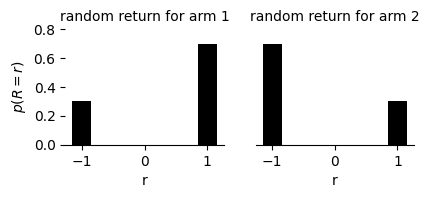

In [ ]:
#| label: fig-tab
#| fig-cap: "Random return for each arm of the 1-state two-armed bandit."

## Plot the return distributions

x = tab_1s.Rdict['x']
p = tab_1s.Rdict['p']

# Plot
fig, axes = plt.subplots(1, 2, figsize=(4.5, 1.5))
for a, ax in enumerate(axes):
    ax.spines[['right', 'top', 'left']].set_visible(False)
    ax.bar(x[0,0,a][0], p[0,0,a][0], width=0.3, color='k')
    ax.set_xlabel("r")
    ax.set_ylim([0,0.8])
    ax.set_title("random return for arm "+str(a+1), fontsize=10)
axes[0].set_ylabel(r'$p(R = r)$')
axes[1].set_yticklabels([])
axes[1].set_yticks([])

### Stochastic two-armed bandit with continuous return

In a stochastic two-armed bandit with continuous return, the random return follows a continuous distribution.

Let's consider the following example, in which an agent can choose between two arms: 
* the first arm gives a random return that follows a Gaussian distribution, centered around $\mu = 1$, with standard deviation $\sigma = 0.5$
* the second arm gives a random return that follows a Gaussian distribution, centered around $\mu = -1$, with standard deviation $\sigma = 2.0$

In [ ]:
# Define environment

distA = ('norm', 1, 0.5)  # first arm
distB = ('norm', -1, 2)  # second arm

tab_cr = TwoArmedBandit(distA=distA, distB=distB, 
                        disttype="continuous")
tab_cr

DistTwoArmedBanditOneState_norm_1_norm_-1

Now let's plot the distribution of the random return for each arm. 

[]

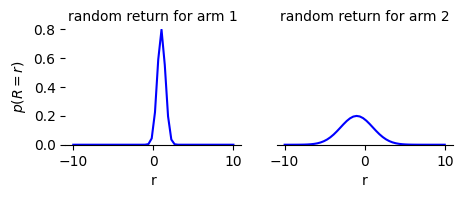

In [ ]:
#| label: fig-tab_cr
#| fig-cap: "Random return distributions for each arm of the stochastic bandit."

## Plot the return distributions

x = np.linspace(-10, 10)
norm1 = stats.norm.pdf(x, 1, 0.5)  # first arm
norm2 = stats.norm.pdf(x, -1, 2)  # second arm
norms = [norm1, norm2]

# Plot
fig, axes = plt.subplots(1, 2, figsize=(5, 1.5))
for s_, ax in enumerate(axes):
    ax.spines[['right', 'top', 'left']].set_visible(False)
    ax.plot(x, norms[s_], color='blue')
    ax.set_xlabel("r")
    ax.set_ylim([0,0.8])
    ax.set_title("random return for arm "+str(s_+1), fontsize=10)
axes[0].set_ylabel(r'$p(R = r)$')
axes[1].set_yticklabels([])
axes[1].set_yticks([])

## Discretization and basic reward distribution $R^{i,s,\boldsymbol{a},\acute s, r}$

### Discretization grid

We assume an agent is equipped with a number $N_r$ of neurons, such that each neuron $i \in [1, N_r]$ is sensitive to an amount of reward $x_i$, with $x_1$ the minimum amount of reward perceived and $x_{N_{r}}$ the maximum amount, and for all $i \in [1, N_r]$ $x_i = x_1 + (i - 1) \frac{x_{N_r} - x_1}{N_r - 1}$. 

The discretization grid is the set ${x_i, i \in [1, N_r]}$ of perceived amounts of rewards (also called "grid points"). We call "width" the difference $\Delta x = (i - 1) \frac{x_{N_r} - x_1}{N_r - 1}$ between two consecutive grid points.

The discretization grid will be the support of all subsequent distributions.

In [ ]:
#| export
def compute_discretization_grid(Rmin, # Minimum reward perceived
                                Rmax, # Maximum reward perceived
                                Nr # Number of gridpoints
                                ) -> tuple: # Gridpoints, Width 
    """
    Compute discretization grid (rewards neurons are sensitive to) 
    for base DDRL agent.        
    """
    gridpoints = np.linspace(Rmin, Rmax, Nr)
    width  = np.round(gridpoints[1] - gridpoints[0], 8)
    return gridpoints, width

### Basic reward distribution $R^{i,s,\boldsymbol{a},\acute s, r}$

Let us now consider a stochastic game with reward tensor $\boldsymbol{R}$ and transition tensor $\boldsymbol{T}$. For all $x \in (x_j)_{j \in [1, N_r]}$, we define the reward distribution $R^{i,s,\boldsymbol{a}, \acute s,r}$ for agent $i$, current state $s$, joint action $\boldsymbol{a}$, and next state $\acute s$, as:
\begin{equation}
    R^{i,s,\boldsymbol{a}, \acute s,r} = \int_{r - \frac{\Delta x}{2}}^{r + \frac{\Delta x}{2}} \frac{1}{\sqrt{2 \pi \sigma^{2}}} \exp[-\frac{(y - R^{i,s,\boldsymbol{a},\acute s})^2}{2 \sigma^2}] dy.
\end{equation}

Note that each $R^{i,s,\boldsymbol{a},\acute s}$ is an entry of the reward tensor $\boldsymbol{R}$. In other terms, for all $r \in (x_j)_{j \in [1, N_r]}$, $R^{i,s,\boldsymbol{a}, \acute s,r}$ is the area under the bell curve centered in $R^{i,s,\boldsymbol{a},\acute s}$, taken between $r - \frac{\Delta x}{2}$ and $r + \frac{\Delta x}{2}$. 

For environments with stochastic returns (such as in the stochastic two-armed bandit task), the entries of the reward tensor are themselves distributions.

If these distributions are continuous, we define $F^{i,s,\boldsymbol{a},\acute s}(r)$ the cumulative distribution function of continuous reward distribution ${}^c R^{i,s,\boldsymbol{a},\acute s}(r)$. Then, we discretize as follows:

\begin{equation}
    R^{i,s,\boldsymbol{a}, \acute s,r} = \int_{r - \frac{\Delta x}{2}}^{r + \frac{\Delta x}{2}} F^{i,s,\boldsymbol{a},\acute s}(y) dy.
\end{equation}

We define a dispatcher function, which associates keywords with corresponding distribution shapes, so that we can compute relevant cumulative distribution functions:

In [ ]:
#| export
def dispatcher():
    dispatcher={'norm':stats.norm, 'alpha':stats.alpha, 'beta':stats.beta,
               'powerlaw':stats.powerlaw}
    return dispatcher

Now we can compute the basic reward distribution for three cases:
- deterministic returns (such as a two-armed bandit task with three states)
- stochastic returns following continuous distributions (such as a stochastic two-armed bandit with continuous return)
- stochastic returns following discrete distributions (such as a one-state two-armed bandit task). 

In [ ]:
#| export
def compute_Risjasr(env, # The env object
                    Rmin,  # minimum perceived reward
                    Rmax,  # maximum perceived reward
                    nr,  # The number of reward bins
                    discretization_sigma # Width of the discritization normal distribution
                   ) -> np.ndarray: # Reward distribution
    """
    Compute basic reward distribution Risjasr.       
    """
    
    # get the discretization grid
    points, width = compute_discretization_grid(Rmin, Rmax, nr)

    # init the reward distribution tensor
    Risjasr = np.zeros(env.R.shape + (nr,))  # last dim is distrib

    # go through the reward tensor of the environment
    for index, _ in np.ndenumerate(env.R):
        if env.disttype == 'continuous':  # return follows continuous distrib
            sigma = env.Rdict['scale'][index]  # sd
            loc = env.Rdict['loc'][index]  # mean
            dist = env.Rdict['dist'][index]  # distribution shape
            # choose the right distribution shape
            disp = dispatcher()
            func = disp[dist]
            # compute discretized distribution
            for r in range(nr):
                if r==0: # first interval
                    prop = func.cdf(points[r]+width/2, loc, sigma)
                elif r==nr-1: # last interval
                    prop = 1 - func.cdf(points[r]-width/2, loc, sigma)
                else: # all other intervals
                    prop = func.cdf(points[r]+width/2, loc, sigma)\
                        - func.cdf(points[r]-width/2, loc, sigma)   
                Risjasr[index +(r,)] = prop
                
        elif env.disttype == None:  # return is deterministic
            loc = env.R[index]  # mean
            sigma = discretization_sigma  # sigma
            func = stats.norm 
            # compute discretized distribution
            for r in range(nr):
                if r==0: # first interval
                    prop = func.cdf(points[r]+width/2, loc, sigma)
                elif r==nr-1: # last interval
                    prop = 1 - func.cdf(points[r]-width/2, loc, sigma)
                else: # all other intervals
                    prop = func.cdf(points[r]+width/2, loc, sigma)\
                        - func.cdf(points[r]-width/2, loc, sigma)   
                Risjasr[index +(r,)] = prop
        
        else:  # return follows discrete distribution
            x = env.Rdict['x'][index]  # values for which prob is non zero
            p = env.Rdict['p'][index]  # prob that return equals those values
            sigma = discretization_sigma  # discretization width
            func = stats.norm
            # compute discretized distribution
            for i in range(len(x)):
                for r in range(nr):
                    if r==0: # first interval
                        prop = p[i] * func.cdf(points[r]+width/2, x[i], sigma)
                    elif r==nr-1: # last interval
                        prop = p[i] * (1 - func.cdf(points[r]-width/2, x[i], sigma))
                    else: # all other intervals
                        prop = p[i] * (func.cdf(points[r]+width/2, x[i], sigma)\
                                       - func.cdf(points[r]-width/2, x[i], sigma))   
                    Risjasr[index +(r,)] += prop

    return Risjasr

Here are the discretized distributions for the three different two-armed bandits:

1. 3-state two-armed bandit

In [ ]:
env = tab_3s
Rmin = -1.5
Rmax = 1.5
nr = 25
sigma = 0.1

gridpoints, width = compute_discretization_grid(Rmin, Rmax, nr)
Rr = compute_Risjasr(env, Rmin, Rmax, nr, sigma)

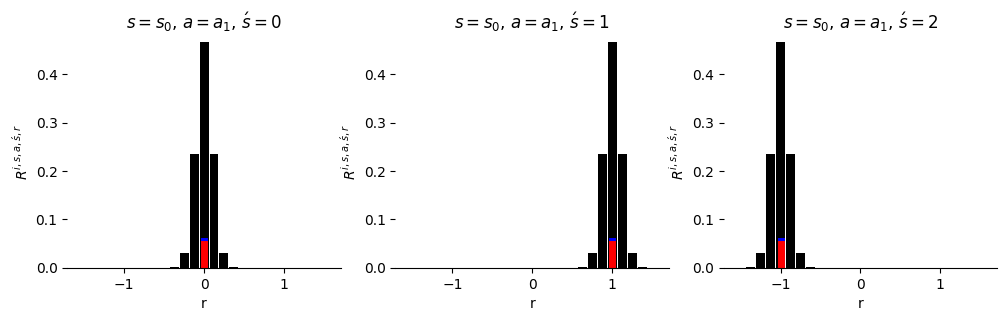

In [ ]:
# Plot reward distribution in each state for first arm
fig, axes = plt.subplots(1, 3, figsize=(12,3))
for s_, ax in enumerate(axes):
    ax.spines[['right', 'top', 'left']].set_visible(False)
    ax.bar(gridpoints, Rr[0,0,0,s_,:], width=0.9*width, color='k')
    r = env.R[0,0,0,s_]
    rm = np.dot(gridpoints, Rr[0,0,0,s_,:])
    ax.plot([r, r], [0.0, 0.055], c='blue', lw=5)
    ax.plot([rm, rm], [0.0, 0.05], c='red', lw=5)
    ax.set_xlabel("r")
    ax.set_ylabel(r"$R^{i,s,a,\acute s, r}$")
    ax.set_title(r'$s=s_0$, $a=a_1$, $\acute s =$'+str(s_))
    ax.set_ylim([0, np.max(Rr[:,:,:,s_])+0.01])

2. 1-state two-armed bandit

In [ ]:
env = tab_1s
Rmin = -1.5
Rmax = 1.5
nr = 25
sigma = 0.1

gridpoints, width = compute_discretization_grid(Rmin, Rmax, nr)
Rr = compute_Risjasr(env, Rmin, Rmax, nr, sigma)

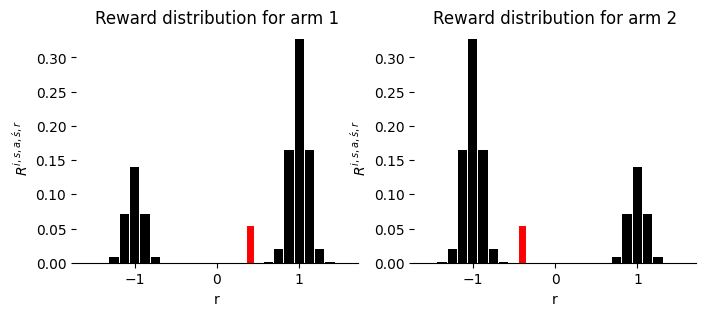

In [ ]:
# Plot reward distribution for both arms
fig, axes = plt.subplots(1, 2, figsize=(8,3))
for a, ax in enumerate(axes):
    ax.spines[['right', 'top', 'left']].set_visible(False)
    ax.bar(gridpoints, Rr[0,0,a,0,:], width=0.9*width, color='k')
    rm = np.dot(gridpoints, Rr[0,0,a,0,:])
    ax.plot([rm, rm], [0.0, 0.05], c='red', lw=5)
    ax.set_xlabel("r")
    ax.set_ylabel(r"$R^{i,s,a,\acute s, r}$")
    ax.set_title("Reward distribution for arm "+str(a+1))
    ax.set_ylim([0, np.max(Rr[:,:,a,:])+0.01])

3. Stochastic two-armed bandit with continuous return

In [ ]:
env = tab_cr
Rmin = -10
Rmax = 10
nr = 29
sigma = 0.1

gridpoints, width = compute_discretization_grid(Rmin, Rmax, nr)
Rr = compute_Risjasr(env, Rmin, Rmax, nr, sigma)

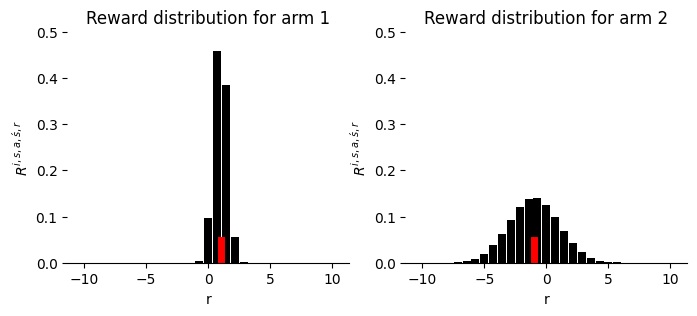

In [ ]:
# Plot reward distribution for both arms
fig, axes = plt.subplots(1, 2, figsize=(8,3))
for a, ax in enumerate(axes):
    ax.spines[['right', 'top', 'left']].set_visible(False)
    ax.bar(gridpoints, Rr[0,0,a,0,:], width=0.9*width, color='k')
    rm = np.dot(gridpoints, Rr[0,0,a,0,:])
    ax.plot([rm, rm], [0.0, 0.05], c='red', lw=5)
    ax.set_xlabel("r")
    ax.set_ylabel(r"$R^{i,s,a,\acute s, r}$")
    ax.set_title("Reward distribution for arm "+str(a+1))
    ax.set_ylim([0, 0.5])

## Smoothed Bellman Kronecker delta $\delta^{i,v,r,\acute v}$

In traditional, expected-value RL, the value of a state $s$ for agent $i$ is computed via the Bellman equation:

$$ V^{i,s} = (1 - \gamma^{i}) R^{i,s} + \gamma^{i} V^{i, \acute s} $$
where $V^{i,\acute s}$ is the value of the next state, $\acute s$.  

In distributional form, we want to compute the probability that (discretized) values $r$, $v$ and $\acute v$ satisfy the Bellman equation $v = (1-\gamma^i)r + \gamma^i \acute v$. To this end, we introduce the smoothed Bellman Kronecker delta, which also allows for some uncertainty about the categorization into different bins. This uncertainty is also modulated by the discretization standard deviation, $\sigma$. Calling $val(r,\acute v)$ the expression $(1-\gamma^i)r + \gamma^i \acute v$,
\begin{equation}
    \delta^{i,v,r,\acute v} = \int_{v - \frac{w}{2}}^{v + \frac{w}{2}} \frac{1}{\sqrt{2 \pi \sigma^{2}}} \exp[-\frac{[y - val(r,\acute v)]^2}{2 \sigma^2}] dy.
\end{equation}

The following function computes the Bellman Kronecker delta for given environment, minimum and maximum perceived rewards, number of neurons, and discount factors:

In [ ]:
#| export    
# Smoothed Bellman Kronecker delta for Bellman equation
def compute_b_ivrv_(env, # env object
                    Rmin,
                    Rmax,
                    nr, # number of bins
                    discretization_sigma, # width of discretization normal distribution
                    gamma,  # discount factor
                    pre  # prefactor
                   ) -> np.ndarray: 
    
    """
    Compute smoothed Bellman Kronecker delta b_ivrv_.       
    """
    
    points, width = compute_discretization_grid(Rmin, Rmax, nr)
    sigma = discretization_sigma
    b_ivrv_ = np.ones((env.N, nr, nr, nr)) * -1

    for v in range(nr):
        for r in range(nr):
            for v_ in range(nr):
                
                valv = pre * points[r] + gamma * points[v_]
                
                # gaussian distribution around valq with std `sig` 
                if v==0:
                    prop = stats.norm.cdf(points[v]+width/2, valv, sigma)
                elif v==nr-1: # last intervall
                    prop = 1 - stats.norm.cdf(points[v]-width/2, valv, sigma)
                else:
                    prop = stats.norm.cdf(points[v]+width/2, 
                                          valv, sigma) - stats.norm.cdf(points[v]-width/2, valv, sigma)
                    
                b_ivrv_[:,v,r,v_] = prop
    return b_ivrv_

## DDRL Base class

Now we can define the DDRL Base class:

In [ ]:
#| export
class DDRLBase(abase):
    """
    Base class for Distributional Deterministic Reinforcement Learning 
    in strategy space.        
    """
    
    def __init__(self,
                 env, # An environment object
                 nr_reward_bins=8, # The number of bins to resolve rewards
                 discretization_sigma=0.1, # standard div for reward discretization
                 learning_rates=0.1, # agents' learning rates
                 discount_factors=0.0, # agents' discount factors
                 Rmin=None,  # minimum perceived reward
                 Rmax=None,  # maximum perceived reward
                 method='mean',  # biasing method
                 tau=0.5,  # tau for expectile and quantile methods
                 wU=1.,  # upper weight for weights method
                 choice_intensities=1.0, # agents' choice intensities
                 opteinsum=True,  # optimize einsum functions
                 use_prefactor=False,  # scale values with rewards
                 **kwargs):

        self.env = env
        Tt = env.T; assert np.allclose(Tt.sum(-1), 1)
        Rt = env.R 
        super().__init__(Tt, Rt, discount_factors, True, opteinsum)
        self.F = jnp.array(env.F)
        
        # learning rates
        self.alpha = make_variable_vector(learning_rates, self.N)

        # intensity of choice
        self.beta = make_variable_vector(choice_intensities, self.N)
        
        # discount factors
        self.gamma = make_variable_vector(discount_factors, self.N)
        
        # pre-factor
        self.pre = 1 - self.gamma if use_prefactor else jnp.ones(self.N)
        
        # number of reward bins
        self.nr = nr_reward_bins
        
        # reward discretization deviation 
        self.discsig = discretization_sigma
        
        # Rmin and Rmax
        if Rmin==None:
            self.Rmin = env.R.min()
        else:
            self.Rmin = Rmin
            
        if Rmax==None:
            self.Rmax = env.R.max()
        else:
            self.Rmax = Rmax
        
        # discretization grid
        disc_grid = compute_discretization_grid(self.Rmin, self.Rmax, self.nr)
        self.gridpoints = disc_grid[0]
        self.gridwidth = disc_grid[1]
        
        # reward tensor distribution
        self.Rr = compute_Risjasr(env, self.Rmin, self.Rmax, self.nr, self.discsig)
        
        # Bellman ivrv_
        self.b_ivrv_ = compute_b_ivrv_(env, self.Rmin, self.Rmax, self.nr, self.discsig, self.gamma, self.pre)
        
        # method
        self.method = method
        
        # value for quantile or expectile
        self.tau = tau
        
        # weights
        self.wU = wU

We consider the following agent-environment interface:
* 1 agent with learning rate $\alpha=0.1$, discount factor $\gamma=0.9$, choice intensity $\beta=4$;
* playing the aforementioned stochastic two-armed bandit task with continuous return.

In [ ]:
aei = DDRLBase(tab_cr,  # environment
               nr_reward_bins=29,
               discretization_sigma=0.1,
               learning_rates=0.1,
               discount_factors=0.9,
               choice_intensities=4.,
               Rmin=-10,
               Rmax=10)

No GPU/TPU found, falling back to CPU. (Set TF_CPP_MIN_LOG_LEVEL=0 and rerun for more info.)


## Computing distributions in DDRL

Now we can compute and plot all the distributions we need.

### Reward distributions $R^{i,s,a^i,r}$ and $R^{i,s,r}$

The basic reward distribution can be averaged over joint actions $\boldsymbol{a}$ and next states $s'$. We call $R^{i,s,a^i,r}$ the reward distribution for agent $i$ taking action $a^i$ in state $s$, averaged over transitions to the next state $\acute s$, and over other agents' actions $\boldsymbol{a}^{-i}$:
\begin{equation}
    R^{i,s,a^i,r} = \sum_{\acute s} \sum_{\boldsymbol{a}^{-i}} \prod_{-i}\boldsymbol{X}^{-i, s, \boldsymbol{a}^{-i}} T^{s,a^i\boldsymbol{a}^{-i},\acute s} R^{i,s,a^i\boldsymbol{a}^{-i},\acute s,r}.
\end{equation}

The reward distribution $R^{i,s,r}$ denotes the probability that agent $i$ receives reward $r$ in state $s$. It is averaged over joint actions $\boldsymbol{a}$ (including agent $i$'s) and next states $s'$:
\begin{equation}
    R^{i,s,r} = \sum_{\acute s} \sum_{\boldsymbol{a}} \prod_{j}\boldsymbol{X}^{j, s, \boldsymbol{a}}\cdot T^{s,\boldsymbol{a},\acute s} \cdot R^{i,s,\boldsymbol{a},\acute s,r}.
\end{equation}

In [ ]:
#| export
@partial(jit, static_argnums=0)
def Risar(self:DDRLBase, 
          Xisa
         ) -> jnp.ndarray:
    
    i = 0; a = 1; s = 2; s_ = 3; r = 4  # Variables
    j2k = list(range(5, 5+self.N-1))  # other agents
    b2d = list(range(5+self.N-1, 5+self.N-1 + self.N))  # all actions
    e2f = list(range(4+2*self.N, 4+2*self.N + self.N-1))  # all other acts
    Risjasr = self.Rr
 
    sumsis = [[j2k[l], s, e2f[l]] for l in range(self.N-1)]  # sum inds
    otherX = list(it.chain(*zip((self.N-1)*[Xisa], sumsis)))

    args = [self.Omega, [i]+j2k+[a]+b2d+e2f] + otherX\
        + [self.T, [s]+b2d+[s_], Risjasr, [i, s]+b2d+[s_, r],
            [i, s, a, r]]
    Risar = jnp.einsum(*args, optimize=self.opti)
    return Risar

DDRLBase.Risar = Risar

We assume the agent chooses arm 1 with probability 0.3, and arm 2 with probability 0.7:

In [ ]:
X = np.ones((1,1,2)) * 0.3
X[:,:,1] = 1 - X[:,:,0]

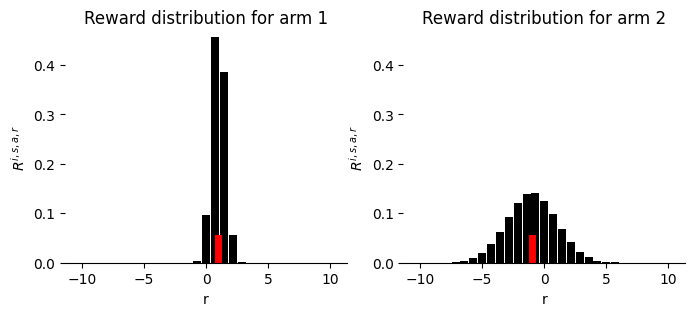

In [ ]:
Rr = aei.Risar(X)

# Plot reward distribution Risar for both arms
fig, axes = plt.subplots(1, 2, figsize=(8,3))
for a, ax in enumerate(axes):
    ax.spines[['right', 'top', 'left']].set_visible(False)
    ax.bar(gridpoints, Rr[0,0,a,:], width=0.9*width, color='k')
    rm = np.dot(gridpoints, Rr[0,0,a,:])
    ax.plot([rm, rm], [0.0, 0.05], c='red', lw=5)
    ax.set_xlabel("r")
    ax.set_ylabel(r"$R^{i,s,a,r}$")
    ax.set_title("Reward distribution for arm "+str(a+1))
    ax.set_ylim([0, np.max(Rr[0,0,:,:]+0.01)])

In [ ]:
#| export
@partial(jit, static_argnums=0)    
def Risr(self:DDRLBase, Xisa):
    """
    Compute reward distribution Risr joint strategy `Xisa`.       
    """
    i = 0; s = 1; sprim = 2; r=3; b2d = list(range(4, 4+self.N))
    Risjasr = jnp.array(self.Rr)
    
    X4einsum = list(it.chain(*zip(Xisa,
                            [[s, b2d[a]] for a in range(self.N)])))

    args = X4einsum + [self.T, [s]+b2d+[sprim],
                       Risjasr, [i, s]+b2d+[sprim, r], [i, s, r]]

    return jnp.einsum(*args, optimize=self.opti)

DDRLBase.Risr= Risr  # Monkey-patching - possibly problematic?

Text(0.5, 1.0, 'Reward distribution in state 0')

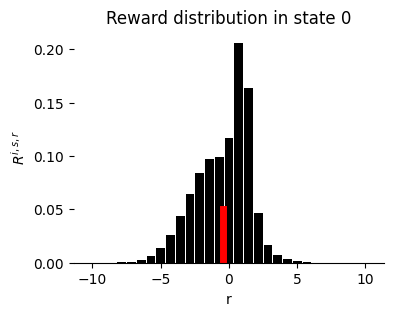

In [ ]:
Rr = aei.Risr(X)

# Plot reward distribution Risar for both arms
fig, ax = plt.subplots(1, 1, figsize=(4,3))
ax.spines[['right', 'top', 'left']].set_visible(False)
ax.bar(gridpoints, Rr[0,0,:], width=0.9*width, color='k')
rm = np.dot(gridpoints, Rr[0,0,:])
ax.plot([rm, rm], [0.0, 0.05], c='red', lw=5)
ax.set_xlabel("r")
ax.set_ylabel(r"$R^{i,s,r}$")
ax.set_title("Reward distribution in state 0")

## Value distribution $V^{i,s,v}$ and biased value

We now calculate the value distribution $V^{i,s,v}$. The probability that the random value $V$ equals $v$ for agent $i$ in state $s$ is a conjunction of the following probabilities:
* that random reward $R$ for agent $i$ in state $s$ equals $r$;
* that there is a transition from state $s$ to state $\acute s$;
* that $v$, $r$ and $\acute v$ conform to the above Bellman equation.


The probability that there is a transition from any state $s$ to any state $\acute s$ is given by the environment's stationary distribution, $\bar T^{s,\acute s}$.

Therefore,
\begin{equation}
    V^{i,s,v} =  \sum_{r, \acute v, \acute s} \delta^{i,v,r,\acute v} R^{i,s,r} \bar T^{s,\acute s} V^{i, \acute s, \acute v}.
\end{equation}

We now define
\begin{equation}
    M^{i,s,v,\acute s,\acute v} = \sum_r \delta^{i,v,r,\acute v} R^{i,s,r} \bar T^{s\acute s}.
\end{equation}

Thus,
\begin{equation}
    V^{i,s,v} =  \sum_{\acute v, \acute s} M^{i,s,v,\acute s,\acute v} V^{i, \acute s, \acute v}
\end{equation}

We can combine the indices $s \times v = w$ and $\acute s \times \acute v = \acute w$. Now, $V^{i,w} = \sum_{\acute w} M^{i, w, \acute w} V^{i,\acute w}$. This makes it apparent that the return distribution should be found in the eigenvalues of the matrix $M$.

The following function computes the matrix $M$:

In [ ]:
#| export
@partial(jit, static_argnums=0)    
def M_iww_(self:DDRLBase, 
           Xisa  # Behavior profiles
          ) -> jnp.ndarray:
    """
    Compute matrix M_iww_ given joint strategy `Xisa`.      
    """
    Tss = self.Tss(Xisa)
    Risr = self.Risr(Xisa)
    b_ivrv_ = self.b_ivrv_

    i=0; v=1; r=2; v_=3; s=4; s_=5

    M = jnp.einsum(b_ivrv_, [i,v,r,v_], Risr, [i, s, r], Tss, 
                   [s, s_], [i, s, v_, s_, v], optimize=self.opti)
    jnp.allclose(M.sum((-2,-1)), 1.0)
    return M

DDRLBase.M_iww_ = M_iww_ 

Now, we can compute the value distribution $V^{i,s,v}$:

In [ ]:
#| export
@partial(jit, static_argnums=0)
def Visv(self:DDRLBase,
        Xisa  # Behavior profiles
        ) -> jnp.ndarray:
    """
    Compute value distribution Visv given joint strategy `Xisa`.      
    """
    
    M_iww_ = self.M_iww_(Xisa)
    Visv = jnp.ones((self.N, self.Z, self.nr)) * -1

    for i in range(self.N):
        mat = M_iww_[i].reshape(self.Z*self.nr, self.Z*self.nr)
        _pS = compute_stationarydistribution(mat)
        ix = jnp.max(jnp.where(_pS.mean(0)!=-10, jnp.arange(_pS.shape[0]), -1))
        pS = _pS[:, ix]
        
        Ps = pS.reshape(self.Z, self.nr).sum(-1)
        # assert jnp.allclose(self.Ps(Xisa), Ps, atol=1e-4)

        VIsv = pS.reshape(self.Z, self.nr) / pS.reshape(self.Z, self.nr).sum(-1, keepdims=True)
        
        Visv = Visv.at[i, ...].set(VIsv)

        # Visv[i, ...] = VIsv

    return Visv

DDRLBase.Visv = Visv 

Here is an example with the above agent-environment interface:

Text(0.5, 1.0, 'Value distribution in state 0')

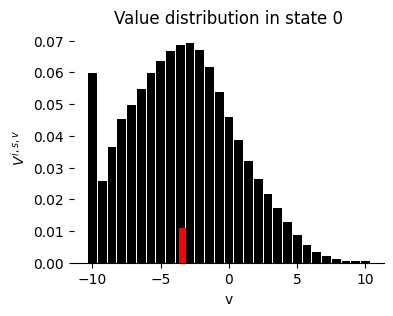

In [ ]:
Vv = aei.Visv(X)

# Plot reward distribution Risar for both arms
fig, ax = plt.subplots(1, 1, figsize=(4,3))
ax.spines[['right', 'top', 'left']].set_visible(False)
ax.bar(gridpoints, Vv[0,0,:], width=0.9*width, color='k')
rm = np.dot(gridpoints, Vv[0,0,:])
ax.plot([rm, rm], [0.0, 0.01], c='red', lw=5)
ax.set_xlabel("v")
ax.set_ylabel(r"$V^{i,s,v}$")
ax.set_title("Value distribution in state 0")

For a neutral agent, the (non-distributional) state value is the mean of the value distribution. But a biased agent will get an optimistic or a pessimistic estimate of this distribution. To obtain this biased estimate, we can apply the quantile, expectile, or weights method to the value distribution. To know more about these methods, please refer to the Biasing Methods section. 

In [ ]:
#| export
@partial(jit, static_argnums=0)
def Vis(self:DDRLBase,
       Xisa  # Behavior profiles
       ) -> jnp.ndarray:
    """
    Compute value estimate Vis given joint strategy `Xisa`.       
    """
    Visv = self.Visv(Xisa)
    gpoints = jnp.ones((self.nr)) * -1
    gpoints = gpoints.at[:].set(self.gridpoints)
    Vism = jnp.einsum('ijk,k->ij', Visv, gpoints)  # mean of the distrib
    if self.method=='mean':  # take mean
        Vis = Vism
    elif self.method=='quantile':  # use quantile
        Vis = quantile(self.tau, Visv, gpoints)
    elif self.method=='expectile':  # use expectile
        Vis = expectile(self.tau, Visv, gpoints)
    elif self.method=='weights':  # use weights
        w = jnp.ones((self.N, self.Z, len(self.gridpoints)))
        n = jnp.newaxis
        upper = self.gridpoints[n,n,:] >= Vism[:,:,n]
        upper = upper * (self.wU - 1)
        w = w + upper
        wVisv = weights(w, Visv, gpoints)
        Vis = jnp.einsum('ijk,k->ij', wVisv, gpoints)  # take the new distrib's mean
    return Vis

DDRLBase.Vis = Vis 

Below, we plot the value distribution, the neutral value (= its mean), and an optimistic estimate implemented with the weights method.

In [ ]:
# Defining an optimistic agent
aei_opt = DDRLBase(tab_cr,  # environment
                   nr_reward_bins=29,
                   discretization_sigma=0.1,
                   learning_rates=0.1,
                   discount_factors=0.9,
                   choice_intensities=4.,
                   method="weights",
                   wU=3.,
                   Rmin=-10,
                   Rmax=10)

Text(0.5, 1.0, 'Value distribution in state 0')

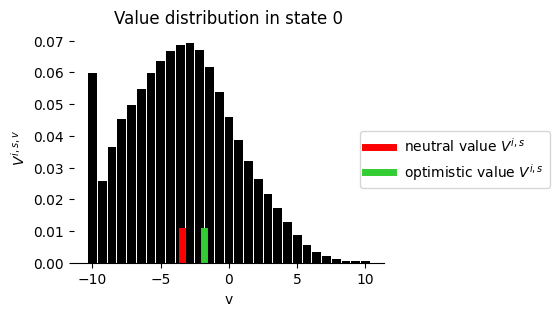

In [ ]:
Vv = aei.Visv(X)
vm = aei.Vis(X)[0,0]
vm_opt = aei_opt.Vis(X)[0,0]

# Plot value distribution Visv
fig, ax = plt.subplots(1, 1, figsize=(4,3))
ax.spines[['right', 'top', 'left']].set_visible(False)
ax.bar(gridpoints, Vv[0,0,:], width=0.9*width, color='k')
ax.plot([vm, vm], [0.0, 0.01], c='red', lw=5, label="neutral value "+r'$V^{i,s}$')
ax.plot([vm_opt, vm_opt], [0.0, 0.01], c='limegreen', 
        lw=5, label="optimistic value "+r'$V^{i,s}$')
ax.set_xlabel("v")
ax.set_ylabel(r"$V^{i,s,v}$")
ax.legend(bbox_to_anchor=(0.9, 0.6))
ax.set_title("Value distribution in state 0")

## Additional functions

The functions below help compute the agents' learning trajectories in strategy space. The first one performs a learning step, while the second one performs a reverse step.

In [ ]:
#|export
@partial(jit, static_argnums=0)
def step(self:DDRLBase,
         Xisa,  # Behavior profiles
        ) -> jnp.ndarray:
    """
    Performs a learning step along the reward-prediction/temporal-difference error
    in strategy space, given joint strategy `Xisa`.
    """
    TDe = self.TDerror(Xisa)
    n = jnp.newaxis
    XexpaTDe = Xisa * jnp.exp(self.alpha[:,n,n] * TDe)
    return XexpaTDe / XexpaTDe.sum(-1, keepdims=True), TDe

DDRLBase.step = step

In [ ]:
#|export
@partial(jit, static_argnums=0)
def reverse_step(self:DDRLBase,
                 Xisa,  # Behavior profiles
                 ) -> jnp.ndarray:
    """
    Performs a reverse learning step along the reward-prediction/temporal-difference error
    in strategy space, given joint strategy `Xisa`.
    """
    TDe = self.TDerror(Xisa)
    n = jnp.newaxis
    XexpaTDe = Xisa * jnp.exp(self.alpha[:,n,n] * -TDe)
    return XexpaTDe / XexpaTDe.sum(-1, keepdims=True), TDe

DDRLBase.reverse_step = reverse_step

In [ ]:
#| hide
nbdev.export.nb_export("02.01_DDRLBase.ipynb", "")